# Prepare samples for evaluation of OpenAI Moderations API 

1. Random sample of nearly 50,000 records from moderated instances --> annotate 500 instances balanced hate vs. not hate
2. Random sample of nearly 50,000 from all instances --> annotate 1500 instances

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from os.path import join
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

## Load manually annotated samples

### Moderated instances sample

In [2]:
moderated = pd.read_csv("moderated_servers_sample_for_manual_annotation.csv",sep=";")

In [4]:
moderated.shape

(2072, 12)

In [6]:
moderated.dropna(subset=["HS (1=YES, 0=NO)"], inplace=True) # drop all rows where no label by human annotator was assigned (we exported a larger sample)

In [7]:
len(moderated)

1038

In [8]:
moderated["HS (1=YES, 0=NO)"].value_counts(dropna=False)

HS (1=YES, 0=NO)
0.0    580
1.0    458
Name: count, dtype: int64

In [9]:
moderated["categories.hate"].value_counts()

categories.hate
False    536
True     502
Name: count, dtype: int64

In [10]:
print(confusion_matrix(moderated["categories.hate"], moderated["HS (1=YES, 0=NO)"]))

[[529   7]
 [ 51 451]]


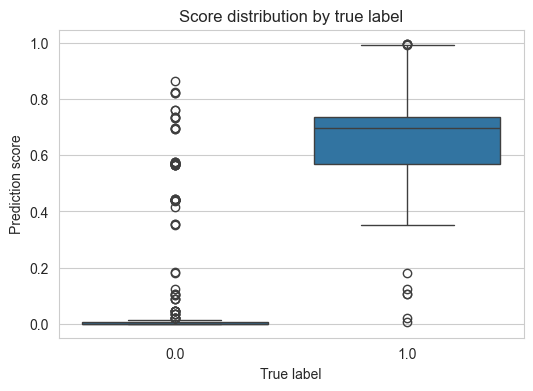

In [11]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=moderated,
    x="HS (1=YES, 0=NO)",
    y="category_scores.hate"
)

plt.xlabel("True label")
plt.ylabel("Prediction score")
plt.title("Score distribution by true label")

plt.show()

### Random Sample

In [17]:
df_sample = pd.read_csv(join("openai_output", "random_sample_for_manual_annotation_with_ground_truth.csv")) # file with predicted labels 
random = pd.read_csv("random_sample_for_manual_annotation.csv", sep=";") # file with manual annotations

In [18]:
random.shape

(1500, 6)

In [19]:
random["HS (1=YES, 0=NO)"].value_counts()

HS (1=YES, 0=NO)
0    1499
1       1
Name: count, dtype: int64

In [20]:
# merge with original output to get true labels
random["categories.hate"] = df_sample["categories.hate"].values

In [21]:
random["category_scores.hate"] = df_sample["category_scores.hate"].values

In [22]:
print(classification_report(random["categories.hate"], random["HS (1=YES, 0=NO)"]))

              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1499
        True       1.00      1.00      1.00         1

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500



In [23]:
df_sample["categories.hate"].value_counts()

categories.hate
False    1499
True        1
Name: count, dtype: int64

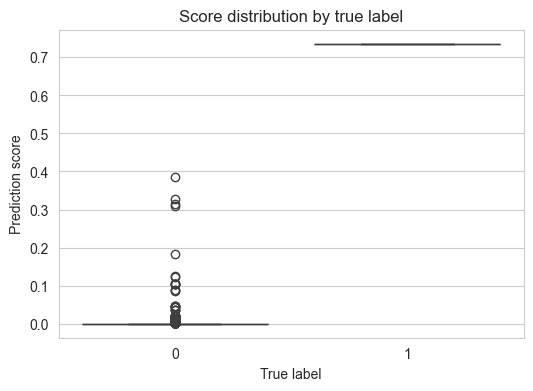

In [24]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=random,
    x="HS (1=YES, 0=NO)",
    y="category_scores.hate"
)

plt.xlabel("True label")
plt.ylabel("Prediction score")
plt.title("Score distribution by true label")

plt.show()

In [25]:
def compute_plot_roc_auc(df, y_true, y_scores): 
    auc = roc_auc_score(df[y_true], df[y_scores])
    print(f"AUC: {auc:.4f}")
    
    fpr, tpr, thresholds = roc_curve(
        df[y_true],
        df[y_scores]
    )
    # Youden's J statistic
    j_stat = tpr - fpr
    best_idx = np.argmax(j_stat)
    
    best_threshold = thresholds[best_idx]
    best_fpr = fpr[best_idx]
    best_tpr = tpr[best_idx]
    
    print(f"Optimal threshold: {best_threshold:.4f}")
    print(f"TPR at optimal threshold: {best_tpr:.4f}")
    print(f"FPR at optimal threshold: {best_fpr:.4f}")
    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
    
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    
    plt.show()



In [64]:
merged = pd.concat([moderated, random], ignore_index=True)

AUC: 0.9918
Optimal threshold: 0.1047
TPR at optimal threshold: 0.9956
FPR at optimal threshold: 0.0327


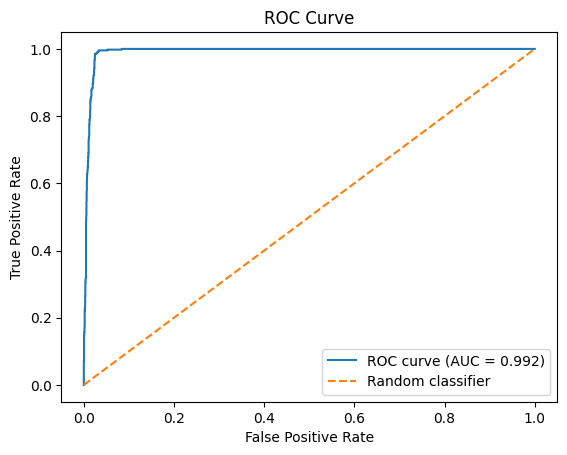

In [65]:
compute_plot_roc_auc(merged, "HS (1=YES, 0=NO)", "category_scores.hate")